# Exercise: Create a BERT sentiment classifier

*Course Exercise 2, completed and extended. Part 1 of 3 in the series on adapting a pre-trained encoder: **4** → [4.1](4.1-full-fine-tuning-bert.ipynb) → [4.2](4.2-linear-probe-vs-full-fine-tuning-vs-lora.ipynb).*

**What this notebook does.** I take a pre-trained DistilBERT encoder, freeze every one of its 66.4M weights, bolt a small classification head on top, and train only that head on 500 IMDB movie reviews. It reaches roughly 80% accuracy while updating less than 1% of the parameters.

**Why I wrote it up this way.** The exercise itself is about ten lines of code. The interesting part is *why* those ten lines work, so I use the exercise as an excuse to go through the whole chain from first principles:

1. What a classifier is, formally (risk, the Bayes classifier, surrogate losses)
2. Softmax and cross-entropy, and the one gradient identity everything rests on
3. How text becomes tensors (WordPiece, `[CLS]`, padding, truncation)
4. What DistilBERT computes, with a parameter count derived by hand and checked in code
5. What "freezing" means mathematically, and what the optimizer actually does
6. Training, then an evaluation that goes beyond a single accuracy number
7. Why a frozen backbone is enough: the geometry of the `[CLS]` representation
8. How the same pattern shows up in production at Google, Anthropic, OpenAI and Netflix

**Where this sits in the repo.**

| Earlier notebook | What it established | How it is used here |
|---|---|---|
| [1 - Generating one token at a time](1-generating-one-token-at-a-time.ipynb) | Tokenization, logits, softmax over a vocabulary | Same softmax, but over 2 classes instead of 50,257 tokens |
| [2.1 - MultiLayerPerceptron](2.1-MultiLayerPerceptron.ipynb) | Forward pass, loss, backprop of a 1-hidden-layer MLP by hand | The classification head here *is* a 1-hidden-layer MLP |
| [2.2 - Sentiment analysis with a transformer](2.2-sentimentAnalysis-transfromer.ipynb) | Using someone else's fine-tuned sentiment model on IMDB | Here I train the classifier instead of downloading it |
| [3.1 - Transfer learning using MobileNetV3](3.1-transfer-learning-using-mobilenetv3.ipynb) | Freeze a vision backbone, train a new head | The identical recipe, applied to language |

The next notebook, [4.1 - Full fine-tuning BERT](4.1-full-fine-tuning-bert.ipynb), removes the freeze. [4.2](4.2-linear-probe-vs-full-fine-tuning-vs-lora.ipynb) then runs both regimes (plus LoRA) on the same data so they can be compared fairly.

## Environment

Tested on an Apple Silicon Mac (MPS backend) with Python 3.13 and the versions pinned in [`requirements.txt`](requirements.txt). Two things differ from the original course notebook because the libraries have moved on:

- Hub ids now need a namespace: `stanfordnlp/imdb` and `distilbert/distilbert-base-uncased`.
- `TrainingArguments(evaluation_strategy=...)` became `eval_strategy`, and `Trainer(tokenizer=...)` became `processing_class`.

In [1]:
import logging
import warnings

warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
transformers.set_seed(42)

# One plotting style for the whole notebook
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "savefig.bbox": "tight",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": SECONDARY,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "lines.linewidth": 2,
        "legend.frameon": False,
    }
)

print(f"torch {torch.__version__} | transformers {transformers.__version__}")

torch 2.14.1 | transformers 5.19.0


## 1. What is a classifier?

Before any transformer shows up, it is worth being precise about the object we are building.

### 1.1 Definition

Let $\mathcal{X}$ be the input space (here: strings of English text) and $\mathcal{Y} = \{0, 1, \dots, K-1\}$ a finite label set (here $K=2$: negative, positive). A **classifier** is a function

$$f : \mathcal{X} \to \mathcal{Y}.$$

We assume examples are drawn i.i.d. from an unknown joint distribution $(x, y) \sim \mathcal{D}$. The quality of a classifier is its **risk**, the probability that it is wrong on a fresh draw:

$$R(f) = \mathbb{E}_{(x,y)\sim\mathcal{D}}\big[\mathbb{1}[f(x) \neq y]\big] = \Pr\big(f(x) \neq y\big).$$

"Accuracy" is just $1 - R(f)$, estimated on a finite test set.

### 1.2 The best possible classifier

Write $\eta_k(x) = \Pr(y = k \mid x)$ for the true posterior. The classifier that minimizes the risk is the **Bayes classifier**

$$f^*(x) = \arg\max_{k}\; \eta_k(x), \qquad R^* = \mathbb{E}_x\big[1 - \max_k \eta_k(x)\big].$$

$R^*$ is the **Bayes error**. It is not zero in general: a review like *"It was fine, I guess"* is genuinely ambiguous, and no model can do better than the label noise allows. This matters when reading results later. An 80% model is not necessarily "20% away from perfect".

### 1.3 Learning: from the 0-1 loss to a surrogate

We never see $\mathcal{D}$, only a sample $\{(x_i, y_i)\}_{i=1}^{n}$. **Empirical risk minimization** replaces the expectation with an average and searches a parametric family $\{f_\theta\}$:

$$\hat\theta = \arg\min_\theta \frac{1}{n}\sum_{i=1}^{n} \ell\big(f_\theta(x_i), y_i\big).$$

The 0-1 loss $\mathbb{1}[f(x)\neq y]$ is piecewise constant, so its gradient is zero almost everywhere and it cannot be minimized by gradient descent. The fix is a **surrogate loss**: a smooth, convex upper bound on the 0-1 loss. For binary labels $y \in \{-1,+1\}$ and a real-valued score $s(x)$, everything can be written in terms of the **margin** $m = y\,s(x)$ (positive means correct):

| Loss | $\ell(m)$ | Used by |
|---|---|---|
| 0-1 | $\mathbb{1}[m \le 0]$ | What we actually care about |
| Logistic (cross-entropy) | $\log_2(1 + e^{-m})$ | Logistic regression, every neural classifier in this repo |
| Hinge | $\max(0, 1 - m)$ | Support vector machines |

The logistic loss is the one neural networks use. It is *classification-calibrated* (Bartlett, Jordan & McAuliffe, 2006): driving the surrogate risk to its minimum also drives the 0-1 risk to the Bayes error, so we lose nothing in the limit by optimizing the easier objective.

### 1.4 The discriminative recipe

Every classifier in this repo has the same two-stage shape:

$$x \;\xrightarrow{\;\phi_{\theta_b}\;}\; \mathbf{h} \in \mathbb{R}^{d} \;\xrightarrow{\;W,\,b\;}\; \mathbf{z} = W\mathbf{h} + b \in \mathbb{R}^{K} \;\xrightarrow{\;\text{softmax}\;}\; p_\theta(y \mid x).$$

A **feature extractor** $\phi$ turns the raw input into a vector, and a **linear layer** turns that vector into one score (logit) per class. In notebook 2 $\phi$ was a hidden layer over pixels. In 3.1 it was MobileNetV3. Here it is DistilBERT. The decision rule is $f_\theta(x) = \arg\max_k z_k$, and because $\mathbf{z}$ is linear in $\mathbf{h}$, the decision boundary between any two classes is a **hyperplane in feature space**. All the non-linearity lives in $\phi$.

The figure below makes both ideas concrete on a toy problem where the Bayes classifier is known in closed form.

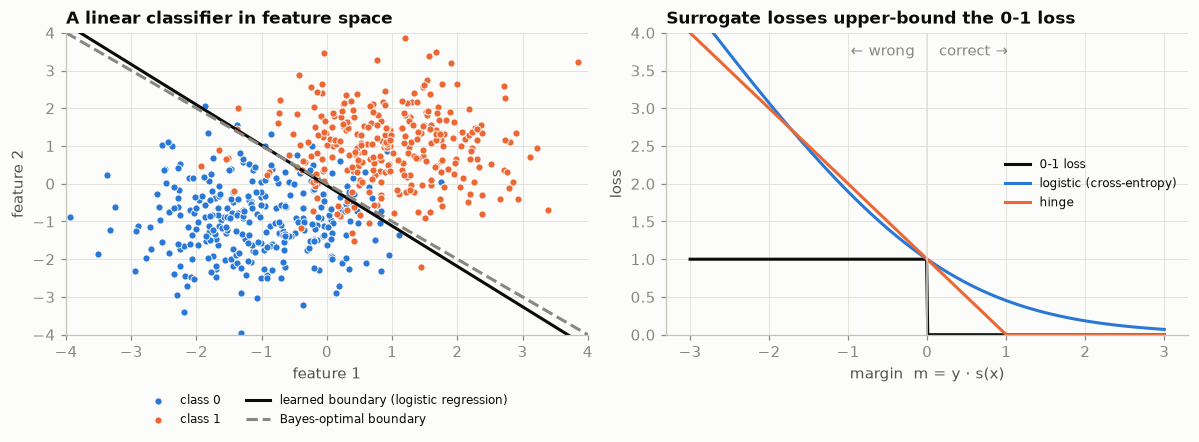

Bayes error (closed form):        0.0786
Learned classifier, 40k new pts:  0.0801


In [2]:
# Figure 1: a classifier on a problem where the Bayes-optimal answer is known
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(0)
mu0, mu1, n_per_class = np.array([-1.0, -1.0]), np.array([1.0, 1.0]), 300
X_toy = np.vstack([rng.normal(mu0, 1.0, (n_per_class, 2)), rng.normal(mu1, 1.0, (n_per_class, 2))])
y_toy = np.repeat([0, 1], n_per_class)

toy_clf = LogisticRegression().fit(X_toy, y_toy)
w, b = toy_clf.coef_[0], toy_clf.intercept_[0]

# Two unit-variance Gaussians with equal priors: the Bayes boundary is the perpendicular
# bisector of the means and the Bayes error is Phi(-||mu1 - mu0|| / 2).
bayes_error = norm.cdf(-np.linalg.norm(mu1 - mu0) / 2)
X_fresh = np.vstack([rng.normal(mu0, 1.0, (20000, 2)), rng.normal(mu1, 1.0, (20000, 2))])
y_fresh = np.repeat([0, 1], 20000)
learned_error = 1 - toy_clf.score(X_fresh, y_fresh)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

for cls, color, name in [(0, BLUE, "class 0"), (1, ORANGE, "class 1")]:
    pts = X_toy[y_toy == cls]
    ax1.scatter(pts[:, 0], pts[:, 1], s=22, color=color, edgecolor=SURFACE, linewidth=0.6, label=name)
xs = np.linspace(-4, 4, 50)
ax1.plot(xs, -(w[0] * xs + b) / w[1], color=INK, label="learned boundary (logistic regression)")
ax1.plot(xs, -xs, color=MUTED, linestyle="--", label="Bayes-optimal boundary")
ax1.set(xlim=(-4, 4), ylim=(-4, 4), xlabel="feature 1", ylabel="feature 2", title="A linear classifier in feature space")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=8)

m = np.linspace(-3, 3, 400)
ax2.plot(m, (m <= 0).astype(float), color=INK, label="0-1 loss")
ax2.plot(m, np.log2(1 + np.exp(-m)), color=BLUE, label="logistic (cross-entropy)")
ax2.plot(m, np.maximum(0, 1 - m), color=ORANGE, label="hinge")
ax2.annotate("← wrong", xy=(-0.15, 3.7), ha="right", color=MUTED)
ax2.annotate("correct →", xy=(0.15, 3.7), ha="left", color=MUTED)
ax2.axvline(0, color=GRID, linewidth=1)
ax2.set(xlabel="margin  m = y · s(x)", ylabel="loss", ylim=(0, 4), title="Surrogate losses upper-bound the 0-1 loss")
ax2.legend(loc="center right", fontsize=8)

fig.tight_layout()
fig.savefig("assets/4-classifier-basics.png")
plt.show()

print(f"Bayes error (closed form):        {bayes_error:.4f}")
print(f"Learned classifier, 40k new pts:  {learned_error:.4f}")

The learned boundary lands almost on top of the Bayes-optimal one, and its error on fresh points matches the closed-form Bayes error to within sampling noise. On this toy problem logistic regression is essentially as good as any classifier can be. The points on the wrong side of the line are not mistakes the model could have avoided; they are the irreducible overlap between the two classes.

The whole premise of this notebook is that a good enough $\phi$ makes real text look like the left panel.

## 2. Softmax, cross-entropy, and the gradient that trains everything

### 2.1 Logits to probabilities

Given logits $\mathbf{z} \in \mathbb{R}^K$:

$$p_k = \mathrm{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j} e^{z_j}}.$$

With $K = 2$ this collapses to the sigmoid of the logit *difference*:

$$p_1 = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0).$$

So a two-logit softmax classifier is exactly logistic regression on the features $\mathbf{h}$, with one redundant degree of freedom (adding a constant to both logits changes nothing).

### 2.2 Cross-entropy is maximum likelihood

For a one-hot target $\mathbf{y}$ with true class $c$:

$$\mathcal{L}(\mathbf{z}, c) = -\sum_k y_k \log p_k = -\log p_c .$$

Averaged over the training set this is the negative log-likelihood of the labels under the model, so minimizing cross-entropy is maximum likelihood estimation. In expectation it equals $H(p_{\text{data}}) + \mathrm{KL}(p_{\text{data}}\,\|\,p_\theta)$, and since the entropy term does not depend on $\theta$, we are minimizing the KL divergence from the true conditional distribution to the model.

A useful reference point: a model that knows nothing outputs $p = (0.5, 0.5)$ and scores $\mathcal{L} = \ln 2 \approx 0.693$. Any training loss should be read against that number.

### 2.3 The gradient

Differentiating through the softmax gives the identity I already used in [3.1](3.1-transfer-learning-using-mobilenetv3.ipynb):

$$\frac{\partial \mathcal{L}}{\partial z_k} = p_k - y_k .$$

The error signal is simply "predicted probability minus target". For the final linear layer $\mathbf{z} = W\mathbf{h} + \mathbf{b}$ the chain rule gives

$$\frac{\partial \mathcal{L}}{\partial W} = (\mathbf{p} - \mathbf{y})\,\mathbf{h}^\top, \qquad \frac{\partial \mathcal{L}}{\partial \mathbf{b}} = \mathbf{p} - \mathbf{y}, \qquad \frac{\partial \mathcal{L}}{\partial \mathbf{h}} = W^\top(\mathbf{p} - \mathbf{y}).$$

The last term is what would flow back into the encoder. In this notebook I cut it off there. In 4.1 I let it through.

In [3]:
# Numeric check of section 2 with autograd
import torch.nn.functional as F

h = torch.tensor([[0.5, -1.0, 2.0]])                      # a 3-d "feature vector"
W = torch.tensor([[0.2, -0.4, 0.1], [-0.3, 0.5, 0.6]], requires_grad=True)
bias = torch.zeros(2, requires_grad=True)
target = torch.tensor([0])                                # true class is 0

z = h @ W.T + bias
p = torch.softmax(z, dim=1)
loss = F.cross_entropy(z, target)
loss.backward()

y_onehot = F.one_hot(target, num_classes=2).float()
print(f"logits z            : {z.detach().numpy().round(4)}")
print(f"softmax p           : {p.detach().numpy().round(4)}")
print(f"sigmoid(z1 - z0)    : {torch.sigmoid(z[0, 1] - z[0, 0]).item():.4f}   (equals p[1])")
print(f"loss = -log p[0]    : {loss.item():.4f}   (chance level is ln 2 = {np.log(2):.4f})")
print(f"autograd dL/dW      :\n{W.grad.numpy().round(4)}")
print(f"(p - y) h^T by hand :\n{((p - y_onehot).T @ h).detach().numpy().round(4)}")

assert torch.allclose(W.grad, (p - y_onehot).T @ h, atol=1e-6)
assert torch.allclose(bias.grad, (p - y_onehot)[0], atol=1e-6)

logits z            : [[0.7  0.55]]
softmax p           : [[0.5374 0.4626]]
sigmoid(z1 - z0)    : 0.4626   (equals p[1])
loss = -log p[0]    : 0.6210   (chance level is ln 2 = 0.6931)
autograd dL/dW      :
[[-0.2313  0.4626 -0.9251]
 [ 0.2313 -0.4626  0.9251]]
(p - y) h^T by hand :
[[-0.2313  0.4626 -0.9251]
 [ 0.2313 -0.4626  0.9251]]


## 3. From text to tensors

Now the real data. The [IMDB dataset](https://huggingface.co/datasets/stanfordnlp/imdb) (Maas et al., 2011) has 25,000 training and 25,000 test reviews, balanced between positive and negative. To keep the exercise fast I use a random 500 of each.

In [4]:
# Import the datasets and transformers packages

import datasets
from datasets import load_dataset

datasets.disable_progress_bars()

# Load the train and test splits of the imdb dataset
splits = ["train", "test"]
ds = {split: ds for split, ds in zip(splits, load_dataset("stanfordnlp/imdb", split=splits))}

# Thin out the dataset to make it run faster for this example
for split in splits:
    ds[split] = ds[split].shuffle(seed=42).select(range(500))

for split in splits:
    print(f"{split:5s}: {ds[split].num_rows} reviews, {np.mean(ds[split]['label']):.1%} positive")

ds

train: 500 reviews, 49.2% positive
test : 500 reviews, 49.2% positive


{'train': Dataset({
     features: ['text', 'label'],
     num_rows: 500
 }),
 'test': Dataset({
     features: ['text', 'label'],
     num_rows: 500
 })}

### 3.1 Tokenization

A neural network cannot read characters, so the text has to become a sequence of integers. DistilBERT uses **WordPiece** with a vocabulary of 30,522 entries. Frequent words get their own id; rare words are split into pieces marked with `##`. Two special tokens are added:

- `[CLS]` (id 101) is prepended to every sequence. Its final hidden state is what the classifier reads.
- `[SEP]` (id 102) closes the sequence.

The tokenizer is not converted ahead of time because different models use different vocabularies. Tokenizing at train time keeps the dataset model-agnostic.

In [5]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")


def preprocess_function(examples):
    """Preprocess the imdb dataset by returning tokenized examples."""
    return tokenizer(examples["text"], truncation=True)


tokenized_ds = {}
for split in splits:
    tokenized_ds[split] = ds[split].map(preprocess_function, batched=True)


# Check that we tokenized the examples properly
assert tokenized_ds["train"][0]["input_ids"][:5] == [101, 2045, 2003, 2053, 7189]

# Show the first tokens of the first training example, id by id
first_ids = tokenized_ds["train"][0]["input_ids"]
print(f"vocabulary size: {tokenizer.vocab_size:,}")
print(f"first review   : {ds['train'][0]['text'][:70]}...")
pd.DataFrame({"id": first_ids[:12], "token": tokenizer.convert_ids_to_tokens(first_ids[:12])}).T

vocabulary size: 30,522
first review   : There is no relation at all between Fortier and Profiler but the fact ...


,0,1,2,3,4,5,6,7,8,9,10,11
id,101,2045,2003,2053,7189,2012,2035,2090,3481,3771,1998,6337
token,[CLS],there,is,no,relation,at,all,between,fort,##ier,and,profile


### 3.2 Truncation and padding

Two practical constraints follow from the architecture:

**Truncation.** DistilBERT has learned position embeddings for positions 0 to 511 and nothing beyond, so `truncation=True` cuts every review at 512 tokens. Self-attention also costs $O(n^2 d)$ in sequence length $n$, so long inputs are expensive even when they are allowed. Anything a reviewer says after token 512 is invisible to the model.

**Padding.** A batch must be a rectangular tensor, but reviews differ in length. `DataCollatorWithPadding` pads each batch to the length of *its own* longest member (dynamic padding) and builds an `attention_mask` $\in \{0,1\}^n$ so padded positions are ignored by attention. Padding per batch instead of to a global 512 is purely an efficiency choice: with batch size 4, the wasted computation is whatever the three shorter reviews fall short of the longest one.

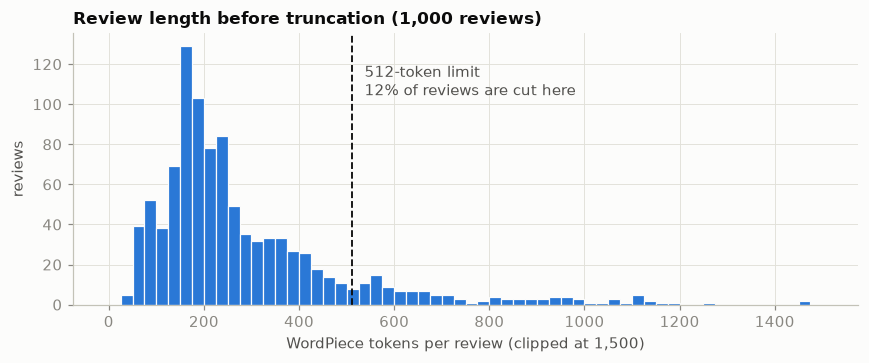

median length: 220 tokens | 90th percentile: 564 | max: 1470


In [6]:
# Figure 2: how long are the reviews, and how many get truncated?
full_lengths = np.array(
    [len(ids) for ids in tokenizer(list(ds["train"]["text"]) + list(ds["test"]["text"]), truncation=False)["input_ids"]]
)
truncated_share = (full_lengths > 512).mean()

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.clip(full_lengths, 0, 1500), bins=np.arange(0, 1525, 25), color=BLUE, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(512, color=INK, linewidth=1.2, linestyle="--")
ax.annotate(
    f"512-token limit\n{truncated_share:.0%} of reviews are cut here",
    xy=(512, ax.get_ylim()[1] * 0.82), xytext=(8, 0), textcoords="offset points", va="center", color=SECONDARY,
)
ax.set(xlabel="WordPiece tokens per review (clipped at 1,500)", ylabel="reviews", title="Review length before truncation (1,000 reviews)")
fig.tight_layout()
fig.savefig("assets/4-token-lengths.png")
plt.show()

print(f"median length: {np.median(full_lengths):.0f} tokens | 90th percentile: {np.percentile(full_lengths, 90):.0f} | max: {full_lengths.max()}")

## 4. Math deep dive: what DistilBERT computes

### 4.1 Embeddings

Token ids $t_1,\dots,t_n$ are mapped to vectors by adding a token embedding and a position embedding, then normalizing:

$$\mathbf{x}_i^{(0)} = \mathrm{LayerNorm}\big(E_{\text{tok}}[t_i] + E_{\text{pos}}[i]\big), \qquad E_{\text{tok}} \in \mathbb{R}^{30522 \times 768},\; E_{\text{pos}} \in \mathbb{R}^{512 \times 768}.$$

### 4.2 Self-attention

Stack the token vectors into $X \in \mathbb{R}^{n\times d}$. One attention head computes

$$Q = XW_Q,\quad K = XW_K,\quad V = XW_V, \qquad \mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V .$$

Row $i$ of the softmax is a probability distribution over all positions, so each output token is a weighted average of every token's value vector. $M$ is the padding mask ($-\infty$ on padded columns). The $\sqrt{d_k}$ keeps the dot products from growing with dimension and saturating the softmax.

DistilBERT uses $A = 12$ heads of size $d_k = 768/12 = 64$, concatenated and projected back to 768.

**Encoder vs decoder.** In [notebook 1](1-generating-one-token-at-a-time.ipynb) GPT-2 used the same formula with a *causal* mask, so token $i$ could only attend to positions $\le i$. BERT-style encoders have no such mask. `[CLS]` at position 0 can attend to the whole review in both directions, which is what makes its final state a usable summary of the full sequence.

### 4.3 The encoder block

Each of the $L = 6$ layers applies attention and a position-wise feed-forward network, each wrapped in a residual connection and LayerNorm:

$$\begin{aligned}
\mathbf{a} &= \mathrm{LayerNorm}\big(\mathbf{x} + \mathrm{MultiHead}(\mathbf{x})\big) \\
\mathbf{x}' &= \mathrm{LayerNorm}\big(\mathbf{a} + W_2\,\mathrm{GELU}(W_1\mathbf{a} + \mathbf{b}_1) + \mathbf{b}_2\big), \qquad W_1 \in \mathbb{R}^{3072\times768},\; W_2 \in \mathbb{R}^{768\times3072}.
\end{aligned}$$

### 4.4 Counting parameters by hand

| Component | Formula | Parameters |
|---|---|---:|
| Token embeddings | $30522 \times 768$ | 23,440,896 |
| Position embeddings | $512 \times 768$ | 393,216 |
| Embedding LayerNorm | $2 \times 768$ | 1,536 |
| **Embeddings total** | | **23,835,648** |
| Attention ($W_Q, W_K, W_V, W_O$ + biases) | $4 \times (768^2 + 768)$ | 2,362,368 |
| Attention LayerNorm | $2 \times 768$ | 1,536 |
| Feed-forward | $(768 \cdot 3072 + 3072) + (3072 \cdot 768 + 768)$ | 4,722,432 |
| Output LayerNorm | $2 \times 768$ | 1,536 |
| **One encoder layer** | | **7,087,872** |
| **Six encoder layers** | $6 \times 7{,}087{,}872$ | **42,527,232** |
| **Backbone total** | | **66,362,880** |
| `pre_classifier` | $768^2 + 768$ | 590,592 |
| `classifier` | $768 \times 2 + 2$ | 1,538 |
| **Head total** | | **592,130** |
| **Whole model** | | **66,955,010** |

Two observations. The token embedding table alone is 35% of the model. And the head is 0.88% of the total, which is the only part this notebook trains.

### 4.5 Where the weights come from: distillation

DistilBERT (Sanh et al., 2019) is a 6-layer student trained to imitate 12-layer BERT-base. Its pre-training loss combines three terms:

$$\mathcal{L} = \alpha\,\mathcal{L}_{\text{distill}} + \beta\,\mathcal{L}_{\text{MLM}} + \gamma\,\mathcal{L}_{\cos}, \qquad \mathcal{L}_{\text{distill}} = -\sum_i t_i^{(T)} \log s_i^{(T)}, \quad s_i^{(T)} = \frac{e^{z_i/T}}{\sum_j e^{z_j/T}} .$$

$\mathcal{L}_{\text{distill}}$ matches the student's temperature-softened distribution $s^{(T)}$ to the teacher's $t^{(T)}$ (Hinton et al., 2015), $\mathcal{L}_{\text{MLM}}$ is the usual masked-language-model loss, and $\mathcal{L}_{\cos}$ aligns the directions of student and teacher hidden states. The paper reports a model 40% smaller and 60% faster than BERT-base that keeps 97% of its language-understanding performance. That trade is why it is the default choice for exercises like this one, and for a lot of latency-sensitive production systems.

## 5. Load the model and freeze the backbone

The sequence-classification head that Hugging Face attaches is

$$\mathbf{h} = \mathrm{ReLU}\big(W_p\,\mathbf{x}^{(L)}_{\texttt{[CLS]}} + \mathbf{b}_p\big), \qquad \mathbf{z} = W_c\,\mathrm{Dropout}_{0.2}(\mathbf{h}) + \mathbf{b}_c .$$

That is a 1-hidden-layer MLP with 768 hidden units, the same object I worked through by hand in [2.1](2.1-MultiLayerPerceptron.ipynb), only fed with DistilBERT's `[CLS]` vector instead of two numbers. Both `pre_classifier` and `classifier` are freshly initialized at random, which is why `from_pretrained` reports them as missing from the checkpoint.

One note on terminology: with the ReLU layer in the head this is strictly an *MLP probe*, not a *linear probe*. I compare it against a true linear probe in section 8.

In [7]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},  # For converting predictions to strings
    label2id={"NEGATIVE": 0, "POSITIVE": 1},
    # PyTorch's fused (SDPA) attention does not support dropout on Apple Silicon (MPS)
    attn_implementation="eager",
)

# Freeze all the parameters of the base model
# Hint: Check the documentation at https://huggingface.co/transformers/v4.2.2/training.html
for param in model.base_model.parameters():
    param.requires_grad = False

model.classifier

Linear(in_features=768, out_features=2, bias=True)

In [8]:
print(model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [9]:
# Check the hand-derived parameter table from section 4.4 against the real model


def count(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


components = {"embeddings": model.distilbert.embeddings}
for i, layer in enumerate(model.distilbert.transformer.layer):
    components[f"encoder layer {i + 1}"] = layer
components["pre_classifier"] = model.pre_classifier
components["classifier"] = model.classifier

param_table = pd.DataFrame(
    [(name, count(mod), count(mod, trainable_only=True)) for name, mod in components.items()],
    columns=["component", "parameters", "trainable"],
)

assert count(model.distilbert.embeddings) == 23_835_648
assert count(model.distilbert.transformer.layer[0]) == 7_087_872
assert count(model.distilbert) == 66_362_880
assert count(model.pre_classifier) + count(model.classifier) == 592_130
assert count(model) == 66_955_010

total, trainable = count(model), count(model, trainable_only=True)
print(f"total parameters    : {total:,}")
print(f"trainable parameters: {trainable:,}  ({trainable / total:.2%})")
param_table

total parameters    : 66,955,010
trainable parameters: 592,130  (0.88%)


,component,parameters,trainable
0,embeddings,23835648,0
1,encoder layer 1,7087872,0
2,encoder layer 2,7087872,0
3,encoder layer 3,7087872,0
4,encoder layer 4,7087872,0
5,encoder layer 5,7087872,0
6,encoder layer 6,7087872,0
7,pre_classifier,590592,590592
8,classifier,1538,1538


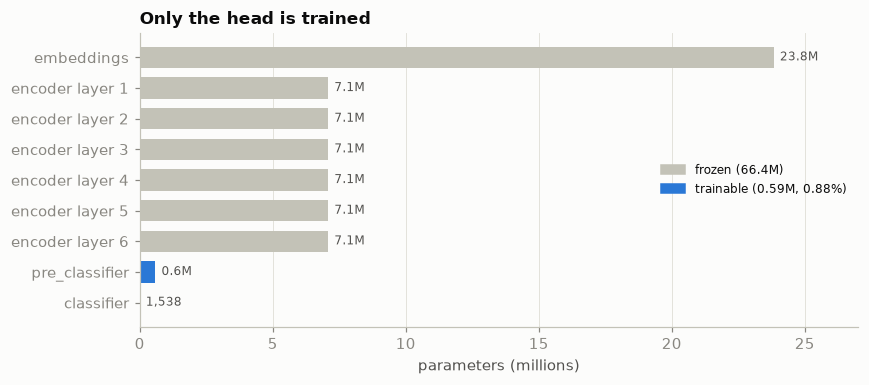

In [10]:
# Figure 3: what is frozen and what trains
FROZEN = "#c3c2b7"
fig, ax = plt.subplots(figsize=(8, 3.6))
order = param_table.iloc[::-1]
colors = [BLUE if t > 0 else FROZEN for t in order["trainable"]]
bars = ax.barh(order["component"], order["parameters"] / 1e6, color=colors, height=0.7)
for bar, n in zip(bars, order["parameters"]):
    label = f"{n / 1e6:.1f}M" if n >= 1e5 else f"{n:,}"
    ax.annotate(label, xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=SECONDARY)
ax.legend(
    handles=[
        Patch(color=FROZEN, label=f"frozen ({(total - trainable) / 1e6:.1f}M)"),
        Patch(color=BLUE, label=f"trainable ({trainable / 1e6:.2f}M, {trainable / total:.2%})"),
    ],
    loc="center right", fontsize=8,
)
ax.grid(axis="y", visible=False)
ax.set(xlabel="parameters (millions)", title="Only the head is trained", xlim=(0, 27))
fig.tight_layout()
fig.savefig("assets/4-frozen-vs-trainable.png")
plt.show()

## 6. What freezing means, and what the optimizer does

### 6.1 Freezing

Split the parameters into backbone and head, $\theta = (\theta_b, \theta_h)$. Setting `requires_grad = False` on $\theta_b$ turns the training problem into

$$\min_{\theta_h}\; \frac{1}{n}\sum_{i=1}^{n} -\log p_{\theta_h}\big(y_i \mid \phi_{\theta_b^{0}}(x_i)\big), \qquad \theta_b \equiv \theta_b^{0} \text{ (pre-trained, constant)}.$$

Three consequences:

1. **Cheaper steps.** The forward pass still runs the whole encoder, but autograd stops at the `[CLS]` vector. No encoder activations are kept for the backward pass and no encoder gradients are computed. Since $\phi(x_i)$ never changes, the features could even be computed once and cached, which is what section 8 does.
2. **A much easier optimization problem.** If the head were only the final linear layer, the objective would be convex in $\theta_h$ (it is logistic regression on fixed features) with a unique optimum that any reasonable optimizer finds. With the extra ReLU layer it is no longer convex, but it is still a tiny, well-conditioned problem.
3. **A hard ceiling.** The model can only separate classes that are *already* separable in the frozen feature space. If the pre-trained `[CLS]` vector does not encode sentiment well, no amount of head training will fix it.

Point 2 is why a learning rate of $2\times10^{-3}$ is fine here. In 4.1, where the pre-trained weights are also updated, that learning rate would destroy them and I drop it by two orders of magnitude.

### 6.2 AdamW

`Trainer` uses AdamW (Loshchilov & Hutter, 2019). With gradient $\mathbf{g}_t = \nabla_\theta \mathcal{L}_t$:

$$\begin{aligned}
\mathbf{m}_t &= \beta_1 \mathbf{m}_{t-1} + (1-\beta_1)\,\mathbf{g}_t, &\hat{\mathbf{m}}_t &= \mathbf{m}_t / (1-\beta_1^t) \\
\mathbf{v}_t &= \beta_2 \mathbf{v}_{t-1} + (1-\beta_2)\,\mathbf{g}_t^2, &\hat{\mathbf{v}}_t &= \mathbf{v}_t / (1-\beta_2^t) \\
\theta_t &= \theta_{t-1} - \eta_t\left(\frac{\hat{\mathbf{m}}_t}{\sqrt{\hat{\mathbf{v}}_t} + \epsilon} + \lambda\,\theta_{t-1}\right)
\end{aligned}$$

with $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$ and weight decay $\lambda = 0.01$. The "W" is the decoupling: the decay term $\lambda\theta$ is applied directly to the weights instead of being added to the gradient, so it is not rescaled by $1/\sqrt{\hat{\mathbf v}}$. `Trainer` exempts biases and LayerNorm weights from decay.

### 6.3 Learning-rate schedule

The default schedule is a linear decay to zero with no warm-up:

$$\eta_t = \eta_0\left(1 - \frac{t}{T}\right), \qquad T = \left\lceil \frac{n}{B} \right\rceil \times \text{epochs} = \left\lceil \frac{500}{4} \right\rceil \times 1 = 125 \text{ steps}.$$

### 6.4 Dropout

During training the head applies dropout with $p = 0.2$: each hidden unit is zeroed with probability $p$ and the survivors are scaled by $1/(1-p)$ so the expected activation is unchanged. At evaluation time dropout is off. With only 500 examples and 592K trainable weights it is the main thing standing between this head and memorizing the training set.

## 7. Let's train it!

`Trainer` wraps the loop I wrote by hand in [3](3-pytorch-and-hugging-face-scavenger-huntscavenger-hunt.ipynb) and [3.1](3.1-transfer-learning-using-mobilenetv3.ipynb): forward, loss, backward, optimizer step, zero the gradients. I keep the exercise's hyperparameters and only add logging every 5 steps so the loss curve can be plotted.

In [11]:
from transformers import DataCollatorWithPadding, PrinterCallback, Trainer, TrainingArguments


def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    return {"accuracy": (predictions == labels).mean()}


# The HuggingFace Trainer class handles the training and eval loop for PyTorch for us.
# Read more about it here https://huggingface.co/docs/transformers/main_classes/trainer
trainer = Trainer(
    model=model,
    args=TrainingArguments(
        output_dir="./data/sentiment_analysis",
        learning_rate=2e-3,
        # Reduce the batch size if you don't have enough memory
        per_device_train_batch_size=4,
        per_device_eval_batch_size=4,
        num_train_epochs=1,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        logging_steps=5,
        seed=42,
        report_to="none",
        dataloader_pin_memory=False,
        disable_tqdm=True,
    ),
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["test"],
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)

trainer.remove_callback(PrinterCallback)  # keep the output short; the loss curve is plotted below

train_output = trainer.train()
print(f"device: {model.device} | steps: {train_output.global_step} | wall time: {train_output.metrics['train_runtime']:.1f}s")

device: mps:0 | steps: 125 | wall time: 10.5s


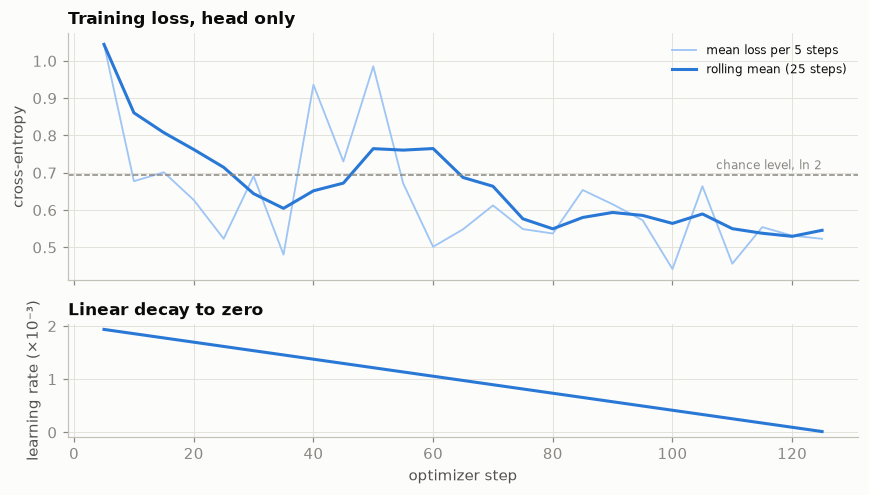

In [12]:
# Figure 4: training loss and the learning-rate schedule (two panels, one x-axis)
log = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h])
smooth = log["loss"].rolling(5, min_periods=1).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
ax1.plot(log["step"], log["loss"], color="#9ec5f4", linewidth=1.2, label="mean loss per 5 steps")
ax1.plot(log["step"], smooth, color=BLUE, label="rolling mean (25 steps)")
ax1.axhline(np.log(2), color=MUTED, linestyle="--", linewidth=1)
ax1.annotate("chance level, ln 2", xy=(log["step"].max(), np.log(2)), xytext=(0, 4), textcoords="offset points",
             ha="right", fontsize=8, color=MUTED)
ax1.set(ylabel="cross-entropy", title="Training loss, head only")
ax1.legend(loc="upper right", fontsize=8)

ax2.plot(log["step"], log["learning_rate"] * 1e3, color=BLUE)
ax2.set(xlabel="optimizer step", ylabel="learning rate (×10⁻³)", title="Linear decay to zero")
fig.tight_layout()
fig.savefig("assets/4-training-curve.png")
plt.show()

**Reading the curve.**

- The first logged loss is about 1.04, *above* the chance level of $\ln 2 \approx 0.693$. A freshly initialized head is not merely uninformed, it is confidently wrong on some examples, and a learning rate of $2\times10^{-3}$ makes the first few updates overshoot.
- The curve is noisy because each step averages over only 4 reviews. With $B = 4$ the standard error of the per-batch loss is large, so individual points mean little. The rolling mean is the thing to look at.
- The loss settles around 0.5 to 0.55 and is still drifting down when the schedule reaches zero. One epoch is not enough to converge the head, which is consistent with section 9, where a solver that *does* run to convergence does slightly better.
- The evaluation loss (0.454) is lower than the final training loss. That is not a sign of a bug. Training loss is measured with dropout on and averaged over steps taken while the head was still poor; evaluation loss is measured once, at the end, with dropout off.

## 8. Evaluate the model

Evaluating the model is as simple as calling the `evaluate` method on the trainer object. This will run the model on the test set and compute the metrics we specified in the `compute_metrics` function.

In [13]:
# Show the performance of the model on the test set
# What do you think the evaluation accuracy will be?
eval_metrics = trainer.evaluate()
eval_metrics

{'eval_loss': 0.4542708396911621,
 'eval_accuracy': 0.804,
 'eval_runtime': 4.5275,
 'eval_samples_per_second': 110.437,
 'eval_steps_per_second': 27.609,
 'epoch': 1.0}

### 8.1 How much should I trust that number?

Accuracy on $n$ test examples is a sample proportion, so it has sampling error. The Wilson score interval for a proportion $\hat p$ at confidence level $1-\alpha$ is

$$\frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}, \qquad z = 1.96 \text{ for } 95\%.$$

With only $n = 500$ the interval is several points wide, which is the right level of humility for everything that follows.

Accuracy also hides *what kind* of mistakes are made. For the positive class, with true/false positives and negatives $TP, FP, TN, FN$:

$$\text{precision} = \frac{TP}{TP+FP}, \qquad \text{recall} = \frac{TP}{TP+FN}, \qquad F_1 = \frac{2\,\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}} .$$

Two threshold-free views complete the picture:

- **ROC AUC** is the probability that a random positive review receives a higher score than a random negative one. It measures ranking quality independently of the 0.5 cut-off.
- **Expected calibration error** asks whether the confidences mean anything. Bin predictions by confidence into $B_1,\dots,B_M$ and compare each bin's accuracy with its mean confidence (Guo et al., 2017):

$$\mathrm{ECE} = \sum_{m=1}^{M} \frac{|B_m|}{n}\,\big|\mathrm{acc}(B_m) - \mathrm{conf}(B_m)\big| .$$

In [14]:
from scipy.special import softmax
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

predictions = trainer.predict(tokenized_ds["test"])
logits, labels = predictions.predictions, predictions.label_ids
probs = softmax(logits, axis=1)
preds = probs.argmax(axis=1)
confidence = probs.max(axis=1)


def wilson_interval(p_hat, n, z=1.96):
    centre = p_hat + z**2 / (2 * n)
    half = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
    return (centre - half) / (1 + z**2 / n), (centre + half) / (1 + z**2 / n)


def expected_calibration_error(confidence, correct, n_bins=10):
    edges = np.linspace(0.5, 1.0, n_bins + 1)  # binary problem: confidence is always >= 0.5
    rows, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > lo) & (confidence <= hi)
        if in_bin.any():
            acc, conf = correct[in_bin].mean(), confidence[in_bin].mean()
            ece += in_bin.mean() * abs(acc - conf)
            rows.append((conf, acc, in_bin.sum()))
    return ece, np.array(rows)


accuracy = (preds == labels).mean()
ci_low, ci_high = wilson_interval(accuracy, len(labels))
auc = roc_auc_score(labels, probs[:, 1])
ece, calibration_bins = expected_calibration_error(confidence, preds == labels)

print(f"accuracy : {accuracy:.3f}   95% Wilson interval [{ci_low:.3f}, {ci_high:.3f}]   (n = {len(labels)})")
print(f"ROC AUC  : {auc:.3f}")
print(f"ECE      : {ece:.3f}\n")
print(classification_report(labels, preds, target_names=["NEGATIVE", "POSITIVE"], digits=3))

accuracy : 0.804   95% Wilson interval [0.767, 0.836]   (n = 500)
ROC AUC  : 0.878
ECE      : 0.054

              precision    recall  f1-score   support

    NEGATIVE      0.839     0.760     0.798       254
    POSITIVE      0.774     0.850     0.810       246

    accuracy                          0.804       500
   macro avg      0.807     0.805     0.804       500
weighted avg      0.807     0.804     0.804       500



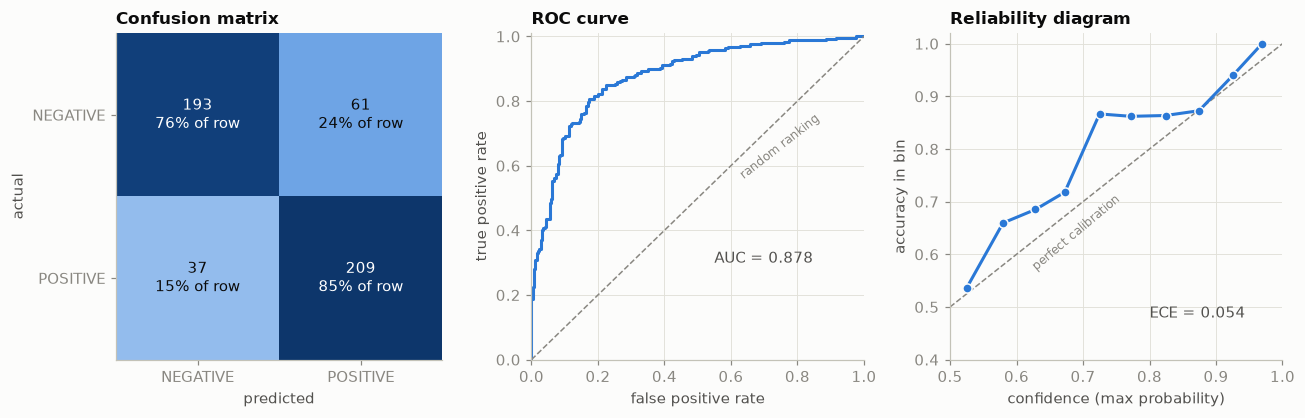

In [15]:
# Figure 5: three views of the same predictions
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3.9))

# (a) confusion matrix
cm = confusion_matrix(labels, preds)
ax1.imshow(cm, cmap=BLUES, vmin=0, vmax=cm.max())
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{cm[i, j]}\n{cm[i, j] / cm[i].sum():.0%} of row", ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() * 0.55 else INK, fontsize=10)
ax1.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["NEGATIVE", "POSITIVE"], yticklabels=["NEGATIVE", "POSITIVE"],
        xlabel="predicted", ylabel="actual", title="Confusion matrix")
ax1.grid(False)

# (b) ROC curve
fpr, tpr, _ = roc_curve(labels, probs[:, 1])
ax2.plot(fpr, tpr, color=BLUE)
ax2.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
ax2.annotate(f"AUC = {auc:.3f}", xy=(0.55, 0.3), color=SECONDARY)
ax2.annotate("random ranking", xy=(0.62, 0.56), rotation=38, fontsize=8, color=MUTED)
ax2.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve", xlim=(0, 1), ylim=(0, 1.01))

# (c) reliability diagram
ax3.plot([0.5, 1], [0.5, 1], color=MUTED, linestyle="--", linewidth=1)
ax3.plot(calibration_bins[:, 0], calibration_bins[:, 1], color=BLUE, marker="o", markersize=6,
         markeredgecolor=SURFACE, markeredgewidth=1)
ax3.annotate("perfect calibration", xy=(0.62, 0.57), rotation=40, fontsize=8, color=MUTED)
ax3.annotate(f"ECE = {ece:.3f}", xy=(0.8, 0.48), color=SECONDARY)
ax3.set(xlabel="confidence (max probability)", ylabel="accuracy in bin", title="Reliability diagram",
        xlim=(0.5, 1), ylim=(0.4, 1.02))

fig.tight_layout()
fig.savefig("assets/4-evaluation.png")
plt.show()

**What the numbers say.**

- **Accuracy is 80.4%, with a 95% interval of roughly 77% to 84%.** The first statement is the measurement; the second is what I am actually entitled to claim. Chance is 50% on this balanced set, so the frozen features clearly carry sentiment.
- **The errors are not symmetric.** 61 negative reviews were called positive against 37 positives called negative, so the model leans positive: recall is 85% on POSITIVE but only 76% on NEGATIVE. With a balanced test set that asymmetry comes from the model, not from class priors. Negative reviews tend to spend many words describing what the film was *trying* to do before dismissing it, which is hard to read off a single summary vector.
- **AUC of 0.878 is noticeably better than the accuracy suggests.** The ranking of reviews by score is good; the fixed 0.5 threshold is just not the best cut. Moving the threshold would trade the two error types against each other without retraining anything.
- **Calibration is reasonable (ECE 0.054) and errs on the side of under-confidence** in the 0.7 to 0.9 range, where accuracy sits above the diagonal. That is the opposite of the over-confidence Guo et al. (2017) report for fully trained deep networks, and it makes sense: this head was trained for one epoch with dropout and never got the chance to push its logits to extremes.

## 9. Why a frozen backbone is enough: the geometry of `[CLS]`

The head only ever sees one 768-dimensional vector per review. If training the head works at all, it is because DistilBERT's pre-training already arranged those vectors so that sentiment is close to linearly separable, even though the model was never shown a sentiment label. This is the idea behind **probing** (Alain & Bengio, 2016): train a simple classifier on frozen activations to measure what information they already contain.

To test this directly I do two things:

1. Extract the frozen `[CLS]` vector for every review and project the test set to 2-D with PCA.
2. Fit a **true linear probe**, plain L2-regularized logistic regression from scikit-learn, on the cached training features. This is the convex problem from section 6.1, solved to its global optimum with no SGD, no learning rate and no dropout.

In [16]:
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader

collator = DataCollatorWithPadding(tokenizer=tokenizer)


@torch.no_grad()
def cls_features(dataset, batch_size=32):
    """Return the frozen backbone's final [CLS] vector for every example."""
    model.eval()
    loader = DataLoader(dataset.remove_columns(["text", "label"]), batch_size=batch_size, collate_fn=collator)
    features = []
    for batch in loader:
        batch = {k: v.to(model.device) for k, v in batch.items()}
        features.append(model.distilbert(**batch).last_hidden_state[:, 0].cpu())
    return torch.cat(features).numpy()


train_features = cls_features(tokenized_ds["train"])
test_features = cls_features(tokenized_ds["test"])
train_labels = np.array(tokenized_ds["train"]["label"])

linear_probe = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=5000))
linear_probe.fit(train_features, train_labels)
probe_accuracy = linear_probe.score(test_features, labels)
probe_low, probe_high = wilson_interval(probe_accuracy, len(labels))

print(f"feature matrix                        : {train_features.shape}")
print(f"MLP head trained with Trainer (sec. 7) : {accuracy:.3f}")
print(f"logistic regression on cached features : {probe_accuracy:.3f}   95% interval [{probe_low:.3f}, {probe_high:.3f}]")

feature matrix                        : (500, 768)
MLP head trained with Trainer (sec. 7) : 0.804
logistic regression on cached features : 0.822   95% interval [0.786, 0.853]


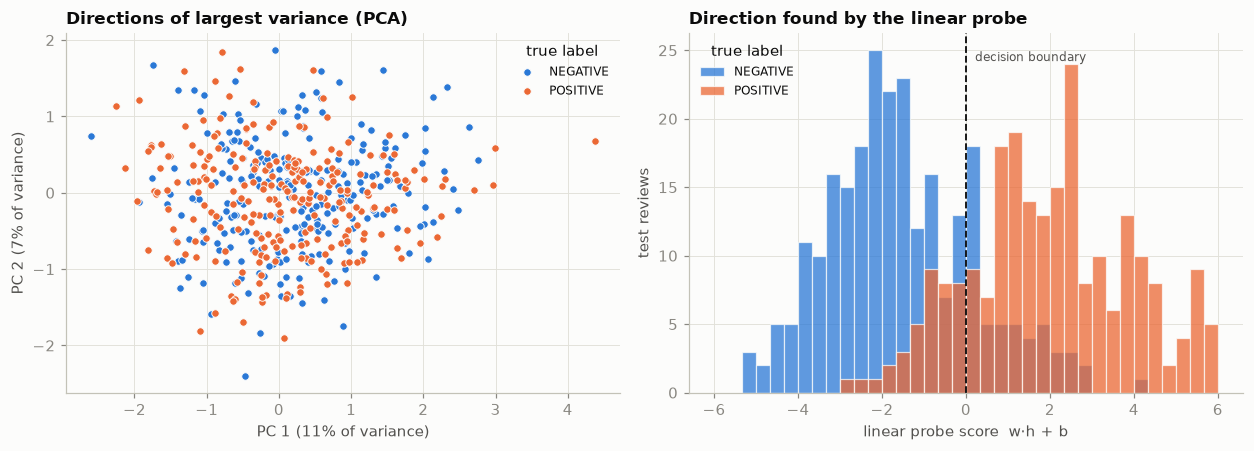

share of (standardized) feature variance along the probe direction: 1.29%


In [17]:
# Figure 6: two 1-D/2-D views of the same 768-d [CLS] vectors (test set)
pca = PCA(n_components=2, random_state=0).fit(train_features)
proj = pca.transform(test_features)
probe_score = linear_probe.decision_function(test_features)  # signed distance to the probe's hyperplane

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
for cls, color, name in [(0, BLUE, "NEGATIVE"), (1, ORANGE, "POSITIVE")]:
    pts = proj[labels == cls]
    ax1.scatter(pts[:, 0], pts[:, 1], s=24, color=color, edgecolor=SURFACE, linewidth=0.6, label=name)
    ax2.hist(probe_score[labels == cls], bins=np.linspace(-6, 6, 37), color=color, alpha=0.75,
             edgecolor=SURFACE, linewidth=0.8, label=name)
ax1.set(
    xlabel=f"PC 1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
    ylabel=f"PC 2 ({pca.explained_variance_ratio_[1]:.0%} of variance)",
    title="Directions of largest variance (PCA)",
)
ax1.legend(loc="upper right", fontsize=8, title="true label")
ax2.axvline(0, color=INK, linewidth=1.2, linestyle="--")
ax2.annotate("decision boundary", xy=(0, ax2.get_ylim()[1] * 0.95), xytext=(6, 0), textcoords="offset points",
             fontsize=8, color=SECONDARY, va="top")
ax2.set(xlabel="linear probe score  w·h + b", ylabel="test reviews", title="Direction found by the linear probe")
ax2.legend(loc="upper left", fontsize=8, title="true label")
fig.tight_layout()
fig.savefig("assets/4-cls-geometry.png")
plt.show()

# How much of the total variance lies along the probe direction?
w_dir = linear_probe[-1].coef_[0] / np.linalg.norm(linear_probe[-1].coef_[0])
standardized = linear_probe[0].transform(train_features)
print(f"share of (standardized) feature variance along the probe direction: {np.var(standardized @ w_dir) / standardized.var(axis=0).sum():.2%}")

**Two findings, and the first one surprised me.**

**1. Sentiment is not what the representation "mostly" encodes.** In the left panel the two classes are completely mixed. The top two principal components account for 18% of the variance and carry essentially no sentiment signal. Whatever those directions capture (topic, length, writing style), it is not whether the reviewer liked the film. I expected at least a visible gradient.

**2. Sentiment is nevertheless linearly decodable.** The right panel projects the *same* vectors onto the single direction found by logistic regression. Along that axis the classes separate into two overlapping but clearly distinct modes, and that direction holds only about 1.3% of the total feature variance.

Put together: a pre-trained encoder stores sentiment in a low-variance direction, not a dominant one. Unsupervised methods that chase variance (PCA, and to a large extent clustering) will miss it. A supervised probe finds it with 500 labels. This is the practical content of "pre-trained representations are linearly separable for downstream tasks", and also a caution against judging a representation by a 2-D PCA plot.

**MLP head vs true linear probe.** Logistic regression on cached features scores 82.2% against 80.4% for the Trainer-trained MLP head. The two intervals overlap almost entirely, so I would not claim the linear probe is *better*. What it does show is that the extra hidden layer and 125 steps of noisy SGD bought nothing over a convex solver that runs in well under a second on features computed once. For a frozen backbone, "extract features, then fit logistic regression" is the baseline to beat.

## 10. View the results

Metrics are a summary. It is always worth reading the actual predictions.

In [18]:
df = pd.DataFrame(tokenized_ds["test"])
df = df[["text", "label"]]

# Replace <br /> tags in the text with spaces
df["text"] = df["text"].str.replace("<br />", " ")

# Add the model predictions to the dataframe
df["predicted_label"] = preds
df["confidence"] = confidence.round(3)
df["tokens"] = full_lengths[500:]  # untruncated length of each test review

df.assign(text=df["text"].str[:200] + "...").head(2)

,text,label,predicted_label,confidence,tokens
0,When I unsuspectedly rented A Thousand Acres...,1,1,0.835,437
1,This is the latest entry in the long series of...,1,1,0.827,240


### Look at some of the incorrect predictions

Let's take a look at some of the incorrectly-predicted examples. I sort by confidence so the most confidently wrong ones come first; those are the most informative.

In [19]:
# Show full cell output
pd.set_option("display.max_colwidth", None)

wrong = df[df["label"] != df["predicted_label"]].sort_values("confidence", ascending=False)
wrong.assign(text=wrong["text"].str[:600] + "...").head(3)

,text,label,predicted_label,confidence,tokens
309,"OK...i have seen just about everything....and some are considered classics that shouldn't be ( like all those Halloween movies that suck crap or even Steven king junk).......and some are considered just OK that are really great.....( like carnival of souls )........and then some are just plain ignored............like ( evil ed ) or ( pumpkin head and brain dead ""the bud Cort one"" ) then some stick in your head once seen and never leave...........that's what this did to me........and for my money this is much better than last house on the left............last house was great till the ending...t...",1,0,0.934,435
90,"Just watched this today on TCM, where the other reviewers here saw it. Sorry that I was the only one to find Davies a weak actress, with a truly awful attempt at an Irish (Irish-American or otherwise) accent. As she's the star, it was sort of hard for me to get past that -- especially as the other reviewers have said that this was her finest performance. Another particularly terrible Davies performance was in ""Marianne"" (1929), which I also watched today. In this film, given a 9 of 10 rating here, her accent switches from that of a (correct) French woman to an odd combination of Italian and ...",0,1,0.928,416
499,"The CinemaScope color cinematography of Leon Shamroy is quite remarkable here,including his use of colored filters for various scenes. The Alfred Newmann Score has to be the most sensual and seductive score Hollywood ever produced. It's a shame it is no longer available on CD. The actors, however, never rise to the occasion. The accents are so varied, from the subdued British of Ustinov and Purdom to the Hollywood of Baxter and Mature that it seems a true hodgepodge with no central vision. Tommy Rettig is jarringly American. Acting styles span the range from zombie-like to stilted. Only Ustin...",0,1,0.913,224


In [20]:
# Does truncation hurt? Accuracy by review length.
df["correct"] = df["label"] == df["predicted_label"]
df["length bucket"] = pd.cut(df["tokens"], bins=[0, 128, 256, 512, 10_000], labels=["≤128", "129-256", "257-512", ">512 (truncated)"])
df.groupby("length bucket", observed=True)["correct"].agg(reviews="size", accuracy="mean").round(3)

,reviews,accuracy
length bucket,,
≤128,72,0.861
129-256,248,0.806
257-512,132,0.788
>512 (truncated),48,0.750


**What the errors look like.**

- The most confident mistakes are reviews whose surface vocabulary points one way while the verdict points the other: a positive review that spends its opening listing other films that "suck", or a negative review that begins by praising the cinematography and the score before turning on the acting. A single frozen summary vector picks up the words more readily than the argument.
- Accuracy falls steadily with length, from 86% for reviews up to 128 tokens to 75% for reviews that hit the 512-token limit. The buckets are small (48 truncated reviews), so the exact numbers are soft, but the direction is what one would expect: long reviews dilute the signal in `[CLS]`, and for truncated ones the conclusion, where reviewers usually state their verdict, may be cut off entirely. Keeping the *last* 512 tokens, or the head and tail together as Sun et al. (2019) suggest, is a simple thing to test.

## 11. How this pattern is used in production

"Keep a big pre-trained model fixed and train something small on top of its activations" is not a classroom simplification. It is a standard way to ship classifiers when the backbone is expensive, shared between tasks, or simply not yours to modify.

**Anthropic: classifiers that reuse the model's own activations.** Anthropic's *Constitutional Classifiers* (Sharma et al., 2025) guard Claude with separate input and output classifiers trained on synthetic data generated from a natural-language "constitution" of allowed and disallowed content. In automated evaluations they report jailbreak success falling from 86% for the unguarded model to 4.4%, at the cost of a 0.38 percentage-point increase in refusals on production traffic and 23.7% extra inference compute. That last figure is the motivation for the follow-up, *Cost-Effective Constitutional Classifiers via Representation Re-use* (Cunningham et al., 2025), which is this notebook's idea at scale: instead of running a second model, train **linear probes on the policy model's intermediate activations**, or **fine-tune only its final layer**. They report that probes match a dedicated classifier 2% the size of the policy model at almost no additional compute, and that final-layer fine-tuning beats standalone classifiers a quarter of the model's size. The authors are careful to add that this still needs testing against adaptive attacks. The correspondence with sections 5 to 9 is direct: frozen backbone, small trained read-out, features computed once.

**Netflix: one foundation model, many consumers.** Netflix's *Foundation Model for Personalized Recommendation* (Netflix Technology Blog, 2025) describes moving from many separately trained recommendation models to one large model trained on member interaction histories. Downstream teams consume it in the ways this repo walks through: use its predictions directly, take its **embeddings** as frozen input features for their own models, or **fine-tune** it for a specific application. The frozen-embedding route is the one in this notebook, and it brings a problem I do not face here: when the foundation model is retrained, the embedding space shifts, and every downstream consumer of the old embeddings is affected.

**Microsoft Bing: distillation is what makes it affordable.** Bing reported in 2019 that it had applied BERT-family models to every query worldwide. The engineering detail that matters for this notebook is that the production model was a **distilled three-layer BERT**: 77 ms per inference on 20 CPU cores, against 6 ms for a batch of 64 on a GPU, served at more than a million inferences per second from over 2,000 GPU VMs. DistilBERT (section 4.5) is the same trade made by a different team.

**Google Search.** Google's 2019 announcement that BERT would "help Search better understand one in 10 searches in the U.S. in English" was the point at which pre-trained encoders became production infrastructure and stopped being a research result. Everything in section 4 is, give or take scale, what was deployed.

**The shared lesson.** At scale the question is rarely "which approach is most accurate?". It is "how much accuracy per unit of compute, and how many tasks can share one forward pass?". A frozen backbone with a cheap head gives up some accuracy for a large saving in both, and when the backbone is already running for another reason, the marginal cost of a probe is close to zero.

## 12. Limitations, and what comes next

Being honest about what this notebook does *not* show:

- **One seed, 500 test reviews.** The confidence interval in section 8 is several points wide. Any claim of the form "method A beats method B by 2 points" needs more data or more seeds than I used here. Notebook 4.2 repeats the experiment over several seeds for that reason.
- **No validation split.** The exercise evaluates on the test split after each epoch and uses `load_best_model_at_end`. With one epoch there is nothing to select, so no leakage occurs, but with more epochs this would be model selection on the test set. A proper setup holds out part of the training data.
- **`[CLS]` was never trained to be a sentence embedding.** BERT's `[CLS]` was pre-trained through next-sentence prediction, and DistilBERT dropped that objective entirely. Its `[CLS]` state is just "whatever position 0 ended up holding". Mean-pooling the token vectors is often suggested as a stronger frozen feature. I test that in [4.2](4.2-linear-probe-vs-full-fine-tuning-vs-lora.ipynb); on this data it made no difference.
- **The ceiling is the backbone.** Freezing gives up the option of adapting the representation to the task. That is the subject of the next notebook.

**Next:** [4.1 - Full fine-tuning BERT](4.1-full-fine-tuning-bert.ipynb) unfreezes all 67M parameters on a different task (SMS spam), and [4.2](4.2-linear-probe-vs-full-fine-tuning-vs-lora.ipynb) puts the frozen head, full fine-tuning and LoRA side by side on IMDB, over several seeds.

## References

**Foundations**
- Bartlett, Jordan & McAuliffe (2006). *Convexity, Classification, and Risk Bounds.* Journal of the American Statistical Association 101(473).
- Vaswani et al. (2017). *Attention Is All You Need.* [arXiv:1706.03762](https://arxiv.org/abs/1706.03762)
- Devlin et al. (2018). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* [arXiv:1810.04805](https://arxiv.org/abs/1810.04805)
- Hinton, Vinyals & Dean (2015). *Distilling the Knowledge in a Neural Network.* [arXiv:1503.02531](https://arxiv.org/abs/1503.02531)
- Sanh, Debut, Chaumond & Wolf (2019). *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter.* [arXiv:1910.01108](https://arxiv.org/abs/1910.01108)
- Loshchilov & Hutter (2017). *Decoupled Weight Decay Regularization.* [arXiv:1711.05101](https://arxiv.org/abs/1711.05101)

**Probing, transfer and evaluation**
- Alain & Bengio (2016). *Understanding intermediate layers using linear classifier probes.* [arXiv:1610.01644](https://arxiv.org/abs/1610.01644)
- Peters, Ruder & Smith (2019). *To Tune or Not to Tune? Adapting Pretrained Representations to Diverse Tasks.* [arXiv:1903.05987](https://arxiv.org/abs/1903.05987)
- Sun, Qiu, Xu & Huang (2019). *How to Fine-Tune BERT for Text Classification?* [arXiv:1905.05583](https://arxiv.org/abs/1905.05583)
- Guo, Pleiss, Sun & Weinberger (2017). *On Calibration of Modern Neural Networks.* [arXiv:1706.04599](https://arxiv.org/abs/1706.04599)
- Maas et al. (2011). *Learning Word Vectors for Sentiment Analysis.* ACL 2011. [aclanthology.org/P11-1015](https://aclanthology.org/P11-1015/)

**Industry**
- Sharma et al., Anthropic (2025). *Constitutional Classifiers: Defending against Universal Jailbreaks across Thousands of Hours of Red Teaming.* [arXiv:2501.18837](https://arxiv.org/abs/2501.18837)
- Cunningham et al., Anthropic Alignment Science (2025). *Cost-Effective Constitutional Classifiers via Representation Re-use.* [alignment.anthropic.com/2025/cheap-monitors](https://alignment.anthropic.com/2025/cheap-monitors/)
- Netflix Technology Blog (2025). *Foundation Model for Personalized Recommendation.* [netflixtechblog.com](https://netflixtechblog.com/foundation-model-for-personalized-recommendation-1a0bd8e02d39)
- Zhu, Microsoft (2019). *Bing delivers its largest improvement in search experience using Azure GPUs.* [azure.microsoft.com](https://azure.microsoft.com/en-us/blog/bing-delivers-its-largest-improvement-in-search-experience-using-azure-gpus/)
- Nayak, Google (2019). *Understanding searches better than ever before.* [blog.google](https://blog.google/products/search/search-language-understanding-bert/)

## End of exercise

Great work! 🤗